# How did the 2025 U.S. Tariffs impact Imports?
Cole Mitchell

Website: https://ColeMitchell1.github.io

Project Goals:

In 2025 the United States raised tariffs on imports from multiple trading partners including China, Canada, and Mexico. Supporters argue tariffs bring production back to the USA, while critics say they lead to price increases and trade disputes. The goal of this project is to test the effects of tariffs. Did U.S. imports shrink, or did they move to other countries? To track this, I will look at major trade partner's share of U.S. imports before and after tariff implementation. The main question is: Did China's share fall, and which, if any countries gained?

Collaboration Plan:

As a Master's student, I will be working alone and will not need a collaboration plan.

# Project Dataset 1

The first dataset comes from the Federal Reserve Bank of St. Louis (FRED) (https://fred.stlouisfed.org/). Each series gives monthly U.S. imports of goods (Millions of dollars, not seasonally adjusted) from one country. For example, (China: https://fred.stlouisfed.org/series/IMPCH ). I downloaded eight trade partners including China, Canada, Mexico, Vietnam, Japan, Germany, South Korea, and India. This data directly measures where imports come from. This data will answer the question: "Did China's share of U.S. imports fall after the tariffs, and who gained?"

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# FRED series IDs for monthly U.S. imports of goods from each partner
SERIES = {
    'IMPCH': 'China',
    'IMPCA': 'Canada',
    'IMPMX': 'Mexico',
    'IMP5520': 'Vietnam',
    'IMPJP': 'Japan',
    'IMPGE': 'Germany',
    'IMPKR': 'South Korea',
    'IMP5330': 'India'}
def load_FRED(series_id):
#Download one FRED series as a CSV
  url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={series_id}"
  df = pd.read_csv(url, na_values='.')
  #Set column 1 as the date and column 2 as the value
  df.columns = ['Date', 'Imports_MUSD']
  df['Date'] = pd.to_datetime(df['Date'])
  return df

#Download each series, label each with the matching country, and add them into one table
frames = []
for series_id, country in SERIES.items():
  d = load_FRED(series_id)
  d['Country'] = country
  frames.append(d)

df_Imports_orig = pd.concat(frames, ignore_index=True)
df_Imports_orig

,Date,Imports_MUSD,Country
0,1985-01-01,293.100000,China
1,1985-02-01,281.000000,China
2,1985-03-01,293.000000,China
3,1985-04-01,283.300000,China
4,1985-05-01,295.100000,China
...,...,...,...
3911,2026-04-01,8260.050168,India
3912,2026-05-01,9136.391175,India
3913,2026-06-01,8887.297577,India
3914,2026-07-01,9581.539920,India


The data goes back to 1985, so I will trim the data to keep only January 2023 and onward. This will create a pre tariff baseline and a post tariff period.

In [11]:
#Keep 2023 and onward
df_Imports = df_Imports_orig[df_Imports_orig['Date'] >= '2023-01-01'].copy()
display(df_Imports.head(10))

#Check the dtypes to confirm they are correct
df_Imports.dtypes


,Date,Imports_MUSD,Country
456,2023-01-01,38157.722699,China
457,2023-02-01,30565.457776,China
458,2023-03-01,30789.177739,China
459,2023-04-01,33074.676730,China
460,2023-05-01,35874.444829,China
461,2023-06-01,34312.055086,China
462,2023-07-01,36112.034255,China
463,2023-08-01,36830.775215,China
464,2023-09-01,40252.484038,China
465,2023-10-01,41561.686424,China


,0
Date,datetime64[ns]
Imports_MUSD,float64
Country,object


In [12]:
#Missing values and tidy checks
display(df_Imports.isna().sum())
#each country should have 44 months
display(df_Imports.groupby('Country')['Date'].count())

,0
Date,0
Imports_MUSD,0
Country,0


,Date
Country,
Canada,44
China,44
Germany,44
India,44
Japan,44
Mexico,44
South Korea,44
Vietnam,44


Checking the dtypes, all are correctly identified, so no type conversion is needed. There are also no missing rows as all countries have 44 months of data. The data is already tidy as each row is one country in one month and each column represents one variable. The main cleaning of this data was labeling each series with its country and filtering the data to January 2023 onward.

# Project Dataset 2

The second dataset also comes from FRED: Federal government current tax receipts (https://fred.stlouisfed.org/series/B235RC1Q027SBEA). This data reports federal customs revenue by quarter, in billions of dollars at a seasonally adjusted annual rate. This dataset shows how much revenue the government collected through tariffs. This will help answer the question "How much did customs revenue rise after the 2025 tariffs, and does it match the shifts in import shares from Dataset 1?" This data is quarterly while the imports are monthly so they will need to be aligned later.

In [13]:
#Downloads the customs dataset from FRED as a CSV
url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=B235RC1Q027SBEA"
df_Duties_orig = pd.read_csv(url, na_values='.')
#Set column 1 as the date and column 2 as the value
df_Duties_orig.columns = ['Date', 'Customs_Duties_BUSD']
df_Duties_orig['Date'] = pd.to_datetime(df_Duties_orig['Date'])

display(df_Duties_orig.head(10))
display(df_Duties_orig.dtypes)



,Date,Customs_Duties_BUSD
0,1959-01-01,0.952
1,1959-04-01,1.076
2,1959-07-01,1.092
3,1959-10-01,1.076
4,1960-01-01,1.176
5,1960-04-01,1.084
6,1960-07-01,1.016
7,1960-10-01,0.988
8,1961-01-01,0.976
9,1961-04-01,0.956


,0
Date,datetime64[ns]
Customs_Duties_BUSD,float64


The data goes back to 1959, so I will keep only 2023 and onward to match the data from Dataset 1. I will also check for missing values.

In [14]:
#Keep 2023 onward
df_Duties = df_Duties_orig[df_Duties_orig['Date'] >= '2023-01-01'].copy()
#Check for missing values
display(df_Duties.isna().sum())

display(df_Duties)
display(df_Duties.dtypes)


,0
Date,0
Customs_Duties_BUSD,0


,Date,Customs_Duties_BUSD
256,2023-01-01,85.687
257,2023-04-01,82.330
258,2023-07-01,78.861
259,2023-10-01,79.653
260,2024-01-01,80.480
261,2024-04-01,79.679
262,2024-07-01,85.084
263,2024-10-01,89.104
264,2025-01-01,103.660
265,2025-04-01,270.592


,0
Date,datetime64[ns]
Customs_Duties_BUSD,float64


This data is already tidy as each row is one quarter. The dtypes are correct and there are no missing values. This data ends earlier than the import data, so I will need to limit the imports to match this dataset when I compare them. Imports and revenue alone won't show the true effect of tariffs, so to strengthen this analysis I plan to add exchange rates and official tariff dates.

# Initial Exploratory Data Analysis

Starting with Dataset 1, I will find each country's share of imports among these eight countries.

In [15]:
#Each country's share of the monthly total across the 8 countries
df_Imports['Basket_Total'] = df_Imports.groupby('Date')['Imports_MUSD'].transform('sum')
df_Imports['Share'] = df_Imports['Imports_MUSD'] / df_Imports['Basket_Total']

#Label each month as before/after the 2025 tariffs
df_Imports['Period'] = np.where(df_Imports['Date'] >= '2025-01-01', 'Post (2025+)', 'Pre (2023-24)')

#Average share by country, before and after tariffs, and the difference
avg_share = df_Imports.groupby(['Country', 'Period'])['Share'].mean().unstack()
avg_share['Change'] = avg_share['Post (2025+)'] - avg_share['Pre (2023-24)']
display(avg_share.sort_values('Change'))

#Average monthly combined imports before vs after (USD millions)
monthly_total = df_Imports.groupby(['Date', 'Period'])['Imports_MUSD'].sum().reset_index()
display(monthly_total.groupby('Period')['Imports_MUSD'].mean())

#China's lowest share month and value
china = df_Imports[df_Imports['Country'] == 'China'].set_index('Date')['Share']
print("China's lowest share:", china.idxmin().date(), round(china.min(), 3))

#China's Share in the first vs last month of the dataset
print("China share in the first month:", round(china.iloc[0], 3), " Latest:", round(china.iloc[-1], 3))

Period,Post (2025+),Pre (2023-24),Change
Country,,,
China,0.145863,0.218940,-0.073076
Canada,0.193364,0.210018,-0.016653
Germany,0.076229,0.080888,-0.004659
Japan,0.072192,0.074479,-0.002286
South Korea,0.069533,0.062628,0.006905
India,0.051074,0.043198,0.007876
Mexico,0.282533,0.246680,0.035853
Vietnam,0.109211,0.063170,0.046041


,Imports_MUSD
Period,
Post (2025+),168681.374875
Pre (2023-24),164850.884767


China's lowest share: 2026-04-01 0.113
China share in the first month: 0.238  Latest: 0.136


From the data, we can see that China's average share of imports from these eight partners fell from 21.9% to 14.6%. This drop of 7.3 percentage points is the largest decline of any country. Vietnam and Mexico gained the most. Because shares add up to 100%, a fall for one country means another country must pick it up. This shows where trade moved but doesn't prove tariffs caused it.

We can also see that average monthly imports from the eight countries were about \$164.9 billion prior to 2025 and \$168.7 billion afterward. This suggests imports from these partners did not shrink overall. This fits the claim that trade moved to other countries rather than declined. It is important to note these numbers are not adjusted for inflation so the actual change is likely smaller.

China's lowest share was in April 2026 at 11.3%. In January 2023, China's share was 23.8%, and in August 2026 it was 13.6%. This shows a sharp decline since the start of the data but it has partly recovered from the April low.

# Dataset 1 Graph

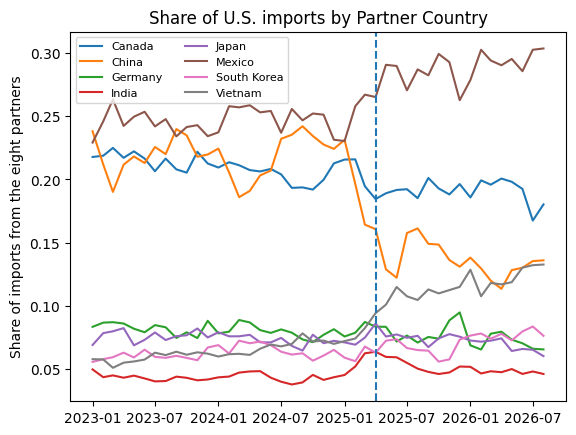

In [16]:
#Reshape data to one column per country
shares = df_Imports.pivot(index='Date', columns='Country', values='Share')
fig, ax = plt.subplots()
#Draw one line per country
for country in shares.columns:
  ax.plot(shares.index, shares[country], label=country)
#Create a dashed vertical line at April 2025 (Quarterly customs revenue first jumps here)
ax.axvline(pd.Timestamp('2025-04-01'), linestyle='--')
#Axis label and title
ax.set_ylabel('Share of imports from the eight partners')
ax.set_title('Share of U.S. imports by Partner Country')
#Edit the legend to not cover the graph
ax.legend(ncol=2, fontsize=8)
plt.show()

The graph shows each country's share of imports from the eight partners, with a dashed line at April 2025. This line represents when customs revenue first jumps. China's share shows the sharpest decline from roughly 23% at the start of 2025 to under 15% in a couple of months. China's share has yet to recover to its pre 2025 level. Vietnam and Mexico both climb, while Canada shows a slight decline. The other countries' shares remain mostly constant.

# Dataset 2 Graph

,Customs_Duties_BUSD
Period,
Post (2025+),284.5
Pre (2023-24),82.6


Latest quarter: 2026-04-01 306.4
Change from the pre-2025 average: 2.71
Highest Quarter: 2025-10-01 366.7


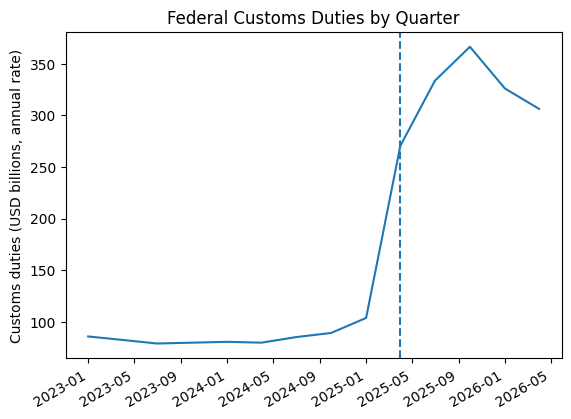

In [17]:
#Label each quarter as before/after 2025
df_Duties['Period'] = np.where(df_Duties['Date'] >= '2025-01-01', 'Post (2025+)', 'Pre (2023-24)')
#Average customs revenue before vs after
display(df_Duties.groupby('Period')['Customs_Duties_BUSD'].mean().round(1))
#Latest quarter and change from the pre-2025 average
pre_avg = df_Duties[df_Duties['Period'] == 'Pre (2023-24)']['Customs_Duties_BUSD'].mean()
latest = df_Duties.iloc[-1]
print("Latest quarter:", latest['Date'].date(), round(latest['Customs_Duties_BUSD'], 1))
print("Change from the pre-2025 average:", round(latest['Customs_Duties_BUSD'] / pre_avg -1, 2))

#Highest Quarter
high = df_Duties.loc[df_Duties['Customs_Duties_BUSD'].idxmax()]
print("Highest Quarter:", high['Date'].date(), round(high['Customs_Duties_BUSD'], 1))

#Graph
fig, ax = plt.subplots()
ax.plot(df_Duties['Date'], df_Duties['Customs_Duties_BUSD'])
ax.axvline(pd.Timestamp('2025-04-01'), linestyle='--')
ax.set_ylabel('Customs duties (USD billions, annual rate)')
ax.set_title('Federal Customs Duties by Quarter')
fig.autofmt_xdate()
plt.show()

The graph shows federal customs revenue by quarter, with a dashed line at April 2025. Revenue remained flat at just below 100 billion USD through 2024, then jumps to over 250 billion USD in the second quarter. It peaked at about 367 billion USD in the fourth quarter of 2025 and dropped to 306 billion USD in the second quarter of 2026. Average quarterly revenue rose from about 82.6 billion USD in 2023-2024 to about 284.5 billion USD from 2025 onward. The latest quarter is about 3.7 times the earlier average. This data shows that tariffs were actually implemented and collected and not just announced. The jump around April 2025 matches the same time when China's share fell in Dataset 1.

In [18]:
from google.colab import drive
drive.mount('/content/drive')
!jupyter nbconvert --to html "/content/drive/MyDrive/Colab Notebooks/Cole Mitchell Milestone 1.ipynb"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[NbConvertApp] Converting notebook /content/drive/MyDrive/Colab Notebooks/Cole Mitchell Milestone 1.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 2 image(s).
[NbConvertApp] Writing 502466 bytes to /content/drive/MyDrive/Colab Notebooks/Cole Mitchell Milestone 1.html
